# 11 — Multimodal ablation

**Research question:** Metadata, ảnh và fusion đóng góp thế nào khi được huấn luyện lại trên cùng người?

Dataset: BodyM silhouettes + provided metadata. Seed 42; proper-fit/tuning/calibration/test tách theo người. Default CNN giữ nguyên.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Module_01_User_and_Body_Profile.md").exists())
for path in [ROOT, ROOT / "scripts"]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
import numpy as np
from IPython.display import display, Markdown
report = json.loads((ROOT / "experiments/bodym_phase3/metrics.json").read_text(encoding="utf-8"))


In [2]:
split = json.loads((ROOT / "experiments/bodym_phase3/subject_split.json").read_text())
groups = [set(split[key]) for key in ["proper_fit_subject_ids", "tuning_subject_ids", "calibration_subject_ids"]]
assert all(not groups[i] & groups[j] for i in range(3) for j in range(i + 1, 3))
print("Subject counts:", report["subject_counts"], "Refit:", report["refit_subjects"])
print("Historical reuse:", report["historical_reuse"])
display(report["training_config"])

Subject counts: {'proper_fit': 1291, 'tuning': 404, 'calibration': 323} Refit: 1695
Historical reuse: Architecture/hyperparameters and test sets were explored in earlier phases; this is not a pristine prospective benchmark.


{'seed': 42,
 'image_height': 128,
 'image_width': 96,
 'padding': 4,
 'channels': [16, 32, 64, 128],
 'metadata_hidden': [32, 16],
 'fusion_hidden': [128, 64],
 'dropout': 0.2,
 'batch_size': 64,
 'max_epochs': 60,
 'patience': 12,
 'learning_rate': 0.001,
 'min_learning_rate': 1e-05,
 'weight_decay': 0.0001,
 'huber_beta': 1.0,
 'calibrate_batchnorm': True,
 'preprocess_workers': 8,
 'cpu_threads': 4}

## Baseline / experiment config

Ba mạng được train từ đầu: MLP metadata; shared CNN hai view không metadata; shared CNN + metadata fusion. Bỏ nhánh khỏi kiến trúc, không che input của model fusion đã train. Chọn epoch bằng 404 tuning subjects rồi refit 1.695 người; calibration 323 người chưa tham gia các bước mới này. Chỉ một seed; không coi đây là causal/statistical proof.

In [3]:
rows = ["| Variant | Params | Epoch | Tune MAE | TestA MAE | TestB MAE |", "|---|---:|---:|---:|---:|---:|"]
for name, result in report["results"].items():
    rows.append(f"| {name} | {result['parameters']} | {result['selection']['selected_epoch']} | {result['selection']['tuning_mean_mae_cm']:.3f} | {result['tests']['testA']['point']['mean_mae_cm']:.3f} | {result['tests']['testB']['point']['mean_mae_cm']:.3f} |")
display(Markdown("\n".join(rows)))
from src.body_vision.analysis import score
for name, result in report["results"].items():
    for test in ["testA", "testB"]:
        with np.load(ROOT / f"data/processed/bodym_phase3/{name}/{test}_predictions.npz") as data:
            recomputed = score(data["y"], data["prediction"], data["subject_ids"])
        assert abs(recomputed["mean_mae_cm"] - result["tests"][test]["point"]["mean_mae_cm"]) < 1e-10
print("Independent point metric checks passed")

| Variant | Params | Epoch | Tune MAE | TestA MAE | TestB MAE |
|---|---:|---:|---:|---:|---:|
| tabular_only | 11283 | 21 | 2.796 | 2.663 | 2.965 |
| image_only | 138739 | 15 | 4.235 | 3.833 | 5.039 |
| fusion | 141443 | 58 | 2.375 | 2.127 | 2.636 |

Independent point metric checks passed


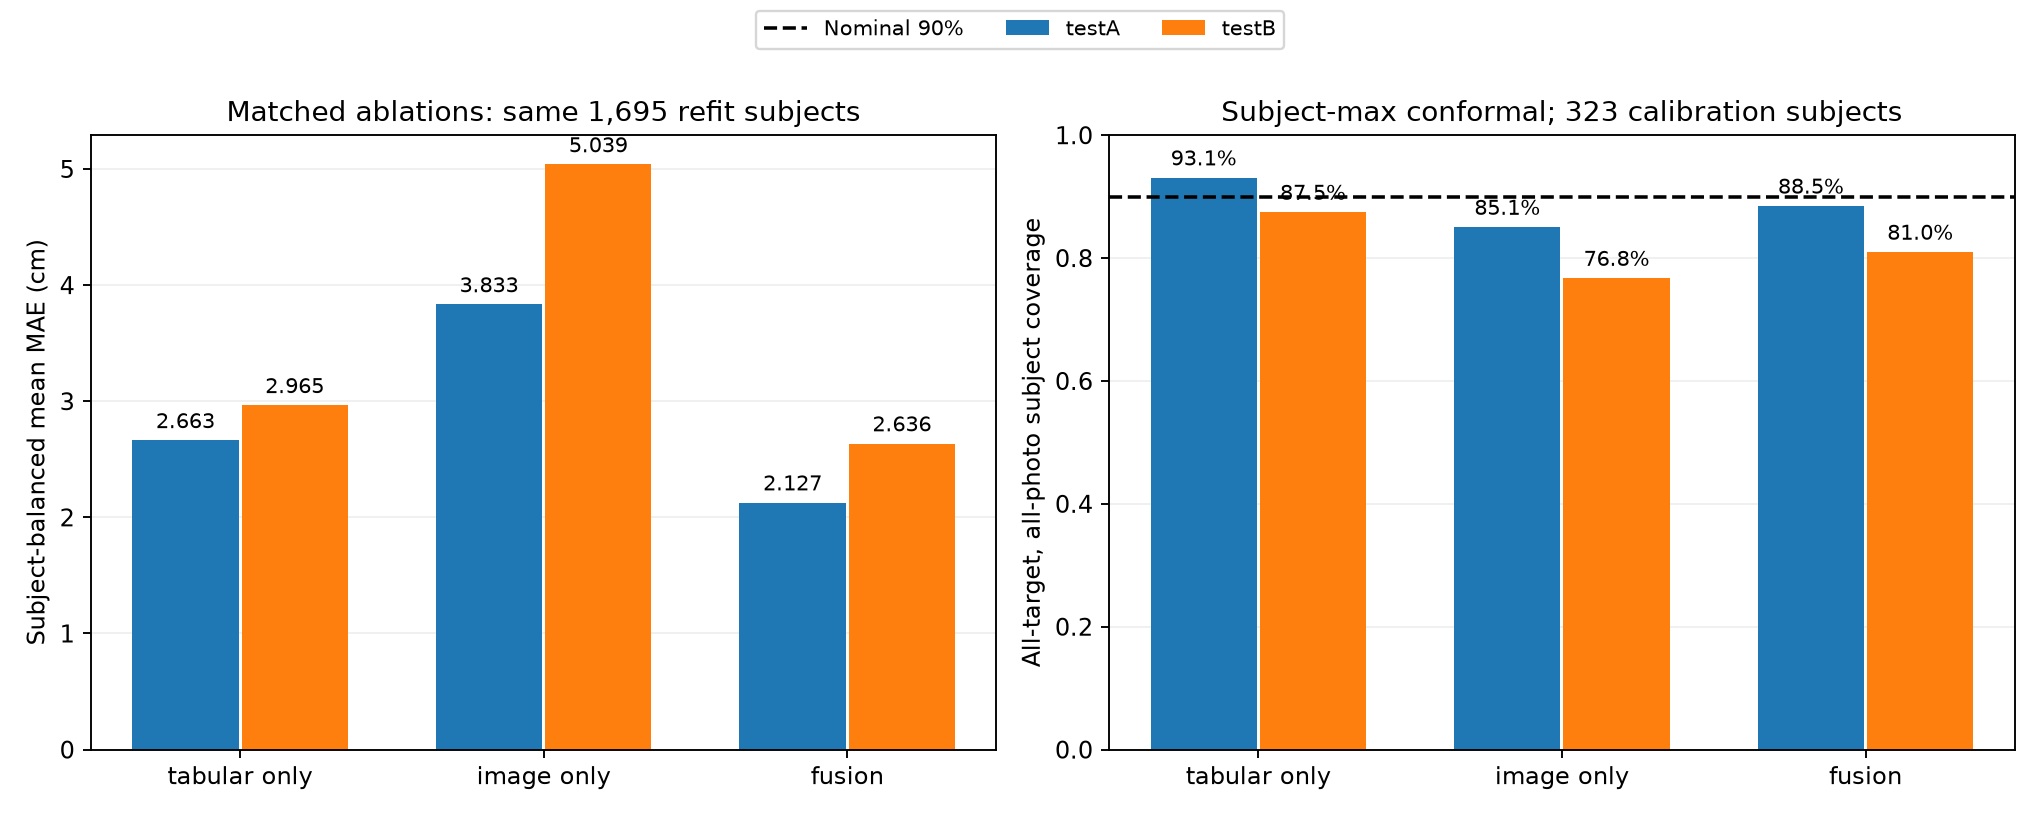

Default checkpoint unchanged


In [4]:
from PIL import Image
display(Image.open(ROOT / "experiments/bodym_phase3/comparison.png"))
import hashlib
default = json.loads((ROOT / "configs/default_model.json").read_text())
assert hashlib.sha256((ROOT / default["checkpoint"]).read_bytes()).hexdigest() == report["default_checkpoint_sha256"]
print("Default checkpoint unchanged")

## Error analysis / conclusion

Xem MAE/RMSE/bias từng chu vi và subgroup JSON để tránh chỉ nhìn trung bình. Không so chênh lệch với Phase 2 như cải thiện thuần kiến trúc: số người fit khác nhau. Dataset/test đã được xem ở phase trước, chưa có test mới prospective hoặc nhiều seed; không tự đổi default theo test. XGBoost/ViT chưa thử ở lượt này.